# Sprint 2 — MVP Analítico
## Análise Espacial da Criminalidade no Brasil — Pré-processamento, Engenharia de Atributos e Modelo Baseline de Risco

**Aluno(a):** Cintia Nunes  
**Curso:** Ciência da Computação — UFFS  
**Disciplina:** Planejamento e Gestão de Projetos — Prof. Fabrício Herpich

Este notebook dá continuidade à Sprint 1 (EDA) e **treina o modelo a partir dos arquivos exportados por ela**. Ele:

1. carrega `sinesp_resumo_2015_2026.csv` (obrigatório), `populacao_uf_ano.csv` (recomendado) e `cobertura_2015_2026.csv` (opcional);
2. constrói um **painel UF × Ano**, tratando como **ausente** (e não como zero) o que as UFs não reportaram;
3. calcula **taxas por 100 mil habitantes** e atributos temporais (defasagens e variação);
4. define o **nível de risco** (Baixo / Médio / Alto) do indicador-alvo por tercis;
5. separa treino e teste **por ano** (sem vazamento temporal);
6. compara modelos com **baselines fortes** (incluindo "repetir o ano anterior"), em holdout e em **validação walk-forward**;
7. avalia com acurácia, F1-macro, **kappa quadrático** e matriz de confusão;
8. exporta o modelo final (`joblib`), as métricas, as previsões e o painel.



## 1. Preparação do ambiente

In [ ]:
import sys
import subprocess
import importlib.util

# módulo importável -> pacote do pip
pacotes = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "requests": "requests",
    "sklearn": "scikit-learn",
    "joblib": "joblib",
}

faltando = [
    pacote for modulo, pacote in pacotes.items()
    if importlib.util.find_spec(modulo) is None
]

if faltando:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltando])

print("Ambiente preparado.")

Ambiente preparado.


In [ ]:
from pathlib import Path
import re
import time
import warnings
import unicodedata

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

PASTA_PROCESSADOS = Path("dados/processados")
PASTA_RESULTADOS = Path("resultados")
PASTA_MODELOS = Path("modelos")

for pasta in [PASTA_PROCESSADOS, PASTA_RESULTADOS, PASTA_MODELOS]:
    pasta.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

try:
    import google.colab  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False


def slug(texto):
    """Nome seguro para colunas e arquivos: sem acentos, minúsculo, com _."""
    t = unicodedata.normalize("NFKD", str(texto).lower())
    t = "".join(c for c in t if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", "_", t).strip("_")


def normalizar_texto(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return " ".join(texto.lower().split())


print("Pastas preparadas. Executando no Colab:", EM_COLAB, "| scikit-learn", sklearn.__version__)

Pastas preparadas. Executando no Colab: True | scikit-learn 1.6.1


## 2. Carregamento dos dados processados na Sprint 1

Arquivos esperados (exportados pela Sprint 1, seção 19):

| Arquivo | Obrigatório? | Uso |
|---|---|---|
| `sinesp_resumo_2015_2026.csv` | **sim** | total por ano, mês, UF, indicador e abrangência |
| `populacao_uf_ano.csv` | recomendado | população da Sprint 1 (se faltar, é consultada no IBGE) |
| `cobertura_2015_2026.csv` | opcional | anos parciais (este notebook também os detecta pelo próprio resumo) |



In [ ]:
USAR_GOOGLE_DRIVE = False
PASTA_GOOGLE_DRIVE = "/content/drive/MyDrive/Sinesp/processados"

NOMES_PADRAO = {
    "resumo": "sinesp_resumo_2015_2026.csv",
    "cobertura": "cobertura_2015_2026.csv",
    "populacao": "populacao_uf_ano.csv",
}

caminhos = {"resumo": None, "cobertura": None, "populacao": None}

if EM_COLAB and USAR_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    base_arquivos = Path(PASTA_GOOGLE_DRIVE)
    for tipo, nome in NOMES_PADRAO.items():
        if (base_arquivos / nome).exists():
            caminhos[tipo] = base_arquivos / nome

elif EM_COLAB:
    from google.colab import files
    print("Selecione 'sinesp_resumo_2015_2026.csv' (obrigatório), 'populacao_uf_ano.csv' e, se tiver, 'cobertura_2015_2026.csv'.")
    for nome in files.upload().keys():
        n = nome.lower()
        for tipo in caminhos:
            if tipo in n:
                caminhos[tipo] = Path(nome)

else:
    for tipo, nome in NOMES_PADRAO.items():
        if (PASTA_PROCESSADOS / nome).exists():
            caminhos[tipo] = PASTA_PROCESSADOS / nome
    print(f"Fora do Colab: procurando em '{PASTA_PROCESSADOS}/'.")

if caminhos["resumo"] is None:
    raise RuntimeError("O arquivo de resumo da Sprint 1 (sinesp_resumo_2015_2026.csv) é obrigatório.")

resumo_sinesp = pd.read_csv(caminhos["resumo"], encoding="utf-8-sig")

# ---- Validação do esquema ----
obrigatorias = ["ano", "mes_numero", "uf", "indicador", "abrangencia", "valor"]
faltam = [c for c in obrigatorias if c not in resumo_sinesp.columns]
if faltam:
    raise RuntimeError(f"O resumo não tem as colunas esperadas: {faltam}. Reexecute a Sprint 1 (v2).")

for col in ["ano", "mes_numero", "valor"]:
    resumo_sinesp[col] = pd.to_numeric(resumo_sinesp[col], errors="coerce")
invalidas = int(resumo_sinesp[["ano", "mes_numero", "valor"]].isna().any(axis=1).sum())
if invalidas:
    print(f"Aviso: {invalidas} linha(s) com ano/mês/valor inválido removida(s).")
resumo_sinesp = resumo_sinesp.dropna(subset=["ano", "mes_numero", "valor"]).copy()
resumo_sinesp[["ano", "mes_numero"]] = resumo_sinesp[["ano", "mes_numero"]].astype(int)
assert (resumo_sinesp["valor"] >= 0).all(), "Há valores negativos no resumo."

# ---- Anos parciais: detectados pelo próprio resumo (e pela cobertura, se enviada) ----
max_mes = resumo_sinesp.groupby("ano")["mes_numero"].max()
anos_parciais = set(max_mes[max_mes < 12].index.tolist())

if caminhos["cobertura"] is not None:
    cobertura = pd.read_csv(caminhos["cobertura"], encoding="utf-8-sig")
    anos_parciais |= set(cobertura.loc[cobertura["mes_final"] < 12, "ano"].astype(int).tolist())

anos_parciais = sorted(int(a) for a in anos_parciais)

print("Registros carregados:", len(resumo_sinesp))
print("Anos disponíveis:", sorted(resumo_sinesp["ano"].unique().tolist()))
print("Anos com cobertura parcial (excluídos da modelagem):", anos_parciais)

resumo_sinesp = resumo_sinesp[~resumo_sinesp["ano"].isin(anos_parciais)].copy()
print("Registros após remover anos parciais:", len(resumo_sinesp))

Selecione 'sinesp_resumo_2015_2026.csv' (obrigatório), 'populacao_uf_ano.csv' e, se tiver, 'cobertura_2015_2026.csv'.


Saving sinesp_resumo_2015_2026.csv to sinesp_resumo_2015_2026.csv
Saving populacao_uf_ano.csv to populacao_uf_ano.csv
Saving cobertura_2015_2026.csv to cobertura_2015_2026.csv
Registros carregados: 48109
Anos disponíveis: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
Anos com cobertura parcial (excluídos da modelagem): [2026]
Registros após remover anos parciais: 46084


## 2.1 Restrição aos 10 indicadores

Mantém apenas os 10 indicadores definidos na Sprint 1. Se o CSV já estiver filtrado, nada é removido.

`INDICADORES_ALTO_VOLUME` é o mesmo conjunto da Sprint 1: indicadores em que **zero no ano (ou meses sem nenhum registro) quase certamente significa "UF não reportou"**.

In [ ]:
INDICADORES_SELECIONADOS = {
    "Estupro": ["estupro"],
    "Estupro de vulnerável": ["estupro de vulneravel"],
    "Feminicídio": ["feminicidio"],
    "Homicídio doloso": ["homicidio doloso"],
    "Lesão corporal seguida de morte": ["lesao corporal seguida de morte"],
    "Morte de Agente do Estado": ["morte de agente do estado"],
    "Roubo seguido de morte (latrocínio)": [
        "roubo seguido de morte (latrocinio)", "roubo seguido de morte", "latrocinio",
    ],
    "Tentativa de feminicídio": ["tentativa de feminicidio"],
    "Tentativa de homicídio": ["tentativa de homicidio"],
    "Tráfico de drogas": ["trafico de drogas"],
}

INDICADORES_ALTO_VOLUME = {
    "Homicídio doloso", "Tentativa de homicídio", "Tráfico de drogas",
    "Estupro", "Estupro de vulnerável",
}

MAPA_ALIASES = {
    alias: nome for nome, aliases in INDICADORES_SELECIONADOS.items() for alias in aliases
}

antes = len(resumo_sinesp)
mapa_nomes = {n: MAPA_ALIASES.get(normalizar_texto(n)) for n in resumo_sinesp["indicador"].unique()}
resumo_sinesp["indicador"] = resumo_sinesp["indicador"].map(mapa_nomes)
resumo_sinesp = resumo_sinesp.dropna(subset=["indicador"]).copy()

# Cada (ano, mês, UF, indicador, abrangência) deve aparecer uma vez; soma se aliases colidirem.
resumo_sinesp = (
    resumo_sinesp
    .groupby(["ano", "mes_numero", "uf", "indicador", "abrangencia"], as_index=False)["valor"]
    .sum()
)

print(f"Registros: {antes} -> {len(resumo_sinesp)}")

ausentes = [n for n in INDICADORES_SELECIONADOS if n not in set(resumo_sinesp["indicador"])]
if ausentes:
    print("ATENÇÃO — indicadores não encontrados no CSV:", ausentes)
else:
    print("Os 10 indicadores foram encontrados.")

Registros: 46084 -> 46084
Os 10 indicadores foram encontrados.


## 3. Escolha do indicador-alvo e parâmetros do experimento

O indicador-alvo é aquele cuja **taxa por 100 mil habitantes** define o **nível de risco** (variável prevista). Os demais entram como atributos auxiliares, junto com o histórico (lag) do próprio alvo.

> Para gerar outro modelo: troque `INDICADOR_ALVO` e execute de novo **a partir desta célula**. Para indicadores de baixo volume (ex.: Feminicídio), UFs pequenas têm taxa instável; interprete com cautela.

In [ ]:
# Opções (os 10 indicadores): Estupro, Estupro de vulnerável, Feminicídio, Homicídio doloso,
# Lesão corporal seguida de morte, Morte de Agente do Estado, Roubo seguido de morte (latrocínio),
# Tentativa de feminicídio, Tentativa de homicídio, Tráfico de drogas.
INDICADOR_ALVO = "Homicídio doloso"

# ---- Parâmetros do experimento ----
# Quantos meses sem registro ainda são tolerados antes de tratar o dado como "não reportado"
# (só para indicadores de alto volume). 0 = rigoroso. Deve ser igual ao usado na Sprint 1.
MESES_SEM_REGISTRO_TOLERADOS = 0

# Primeiro ano usado como LINHA de modelagem (treino/teste). Anos anteriores continuam sendo usados
# para calcular lag1/lag2. None = usar todos os anos elegíveis (a partir de 2017 com a base completa).
# Útil como análise de sensibilidade: ex. 2019 descarta os primeiros anos, de cobertura mais irregular.
ANO_INICIAL_MODELAGEM = None

# Fração dos anos de modelagem reservada ao teste final (os mais recentes).
PROPORCAO_TESTE_ANOS = 0.25

# Cenário PRINCIPAL (os demais aparecem como análise de robustez na seção 11.1):
#   modo de risco: "absoluto" (tercis do treino) ou "relativo" (tercis dentro de cada ano)
#   atributos    : "mesmo_ano" (usa os outros indicadores do próprio ano) ou
#                  "so_historico" (usa apenas informações até o ano anterior = previsão real)
MODO_RISCO_PRINCIPAL = "absoluto"
CONJUNTO_ATRIBUTOS_PRINCIPAL = "mesmo_ano"

indicadores_disponiveis = sorted(resumo_sinesp["indicador"].dropna().unique().tolist())
if INDICADOR_ALVO not in indicadores_disponiveis:
    raise RuntimeError(f"Indicador-alvo inválido: {INDICADOR_ALVO!r}. Use um dos: {indicadores_disponiveis}")

print("Indicador-alvo selecionado:", INDICADOR_ALVO)
print("Cenário principal:", MODO_RISCO_PRINCIPAL, "|", CONJUNTO_ATRIBUTOS_PRINCIPAL)
print("Alto volume?", INDICADOR_ALVO in INDICADORES_ALTO_VOLUME)

Indicador-alvo selecionado: Homicídio doloso
Cenário principal: absoluto | mesmo_ano
Alto volume? True


## 4. Construção do painel UF × Ano (com tratamento de dado não reportado)

O painel agrega o `valor` por UF, ano e indicador (somando abrangências) e coloca cada indicador em uma coluna.

**Regra central (nova):** para indicadores de **alto volume**, se a UF tem **menos meses com registro na abrangência Estadual** do que o ano deveria ter (`12 − tolerância`; PF/PRF atuam em todas as UFs e não contam), o valor anual é considerado **não reportado** e vira `NaN`. Para os demais indicadores, combinações ausentes viram 0 (zeros são plausíveis com poucos casos).

Consequência: se o **alvo** for `NaN` em uma UF×ano, essa linha **não entra** na modelagem nem serve de `lag` para o ano seguinte. Antes, ela entrava como "taxa 0 = risco Baixo".

In [ ]:
# Completude medida SÓ na abrangência Estadual (igual à Sprint 1): PF e PRF atuam em todas as UFs
# e escondem o não-reporte da polícia estadual. O VALOR do painel continua somando todas as abrangências.
ABRANGENCIA_COMPLETUDE = "Estadual"   # None = somar todas
if ABRANGENCIA_COMPLETUDE is not None and ABRANGENCIA_COMPLETUDE not in set(resumo_sinesp["abrangencia"]):
    print(f"Abrangência '{ABRANGENCIA_COMPLETUDE}' não existe nos dados; usando todas.")
    ABRANGENCIA_COMPLETUDE = None

base_meses = (
    resumo_sinesp if ABRANGENCIA_COMPLETUDE is None
    else resumo_sinesp[resumo_sinesp["abrangencia"] == ABRANGENCIA_COMPLETUDE]
)
mensal_comp = base_meses.groupby(["ano", "mes_numero", "uf", "indicador"], as_index=False)["valor"].sum()
meses_reg = (
    mensal_comp.groupby(["ano", "uf", "indicador"])["valor"]
    .agg(meses=lambda s: int((s > 0).sum())).reset_index()
)
valor_anual = resumo_sinesp.groupby(["ano", "uf", "indicador"], as_index=False)["valor"].sum()
anual = valor_anual.merge(meses_reg, on=["ano", "uf", "indicador"], how="outer")

anos_painel = sorted(anual["ano"].unique().tolist())
ufs_painel = sorted(anual["uf"].unique().tolist())
indicadores = [i for i in INDICADORES_SELECIONADOS if i in set(anual["indicador"])]

if any(np.diff(anos_painel) != 1):
    print("ATENÇÃO: há anos faltando na sequência:", anos_painel, "— as defasagens (lag) podem ficar erradas.")

grade_idx = pd.MultiIndex.from_product([anos_painel, ufs_painel], names=["ano", "uf"])

valores_pv = anual.pivot(index=["ano", "uf"], columns="indicador", values="valor").reindex(grade_idx)[indicadores]
meses_pv = anual.pivot(index=["ano", "uf"], columns="indicador", values="meses").reindex(grade_idx)[indicadores]

MESES_MINIMOS = 12 - MESES_SEM_REGISTRO_TOLERADOS
registro_nao_reportado = []

for ind in indicadores:
    if ind in INDICADORES_ALTO_VOLUME:
        invalido = meses_pv[ind].fillna(0) < MESES_MINIMOS
        registro_nao_reportado.append(
            valores_pv.index[invalido.to_numpy()].to_frame(index=False).assign(indicador=ind)
        )
        valores_pv.loc[invalido, ind] = np.nan
    else:
        valores_pv[ind] = valores_pv[ind].fillna(0)

painel = valores_pv.reset_index()
painel.columns.name = None

nao_reportado = pd.concat(registro_nao_reportado, ignore_index=True) if registro_nao_reportado else pd.DataFrame(columns=["ano", "uf", "indicador"])

print("Dimensão do painel UF x Ano:", painel.shape)
print(f"\nUF×ano×indicador (alto volume) tratados como NÃO REPORTADO: {len(nao_reportado)}")
if len(nao_reportado):
    display(
        nao_reportado.groupby(["indicador", "ano"])["uf"]
        .apply(lambda s: ", ".join(sorted(s))).reset_index(name="ufs")
    )

n_alvo_invalido = int(painel[INDICADOR_ALVO].isna().sum())
print(f"\nUF×ano com ALVO ({INDICADOR_ALVO}) não reportado -> excluídos da modelagem: {n_alvo_invalido}")
display(painel.head())

Dimensão do painel UF x Ano: (297, 12)

UF×ano×indicador (alto volume) tratados como NÃO REPORTADO: 121


,indicador,ano,ufs
0,Estupro,2015,"AC, ES, GO"
1,Estupro,2016,"AC, ES, GO"
2,Estupro,2017,"AC, ES"
3,Estupro de vulnerável,2015,"AC, AP, DF, ES, GO, MA, MS, PB, RJ, RO, SP, TO"
4,Estupro de vulnerável,2016,"AC, AP, DF, ES, GO, MA, MS, PB, RJ, RO, SP, TO"
5,Estupro de vulnerável,2017,"AC, AP, DF, ES, MA, MS, PB, RJ, RO, TO"
6,Estupro de vulnerável,2018,"AP, ES, MA, MS, PB, RO, RS, TO"
7,Estupro de vulnerável,2019,"ES, MA, MS, PB, RO, TO"
8,Estupro de vulnerável,2020,"ES, MA, MS, PB, RO"
9,Estupro de vulnerável,2021,"AL, ES, MS, PB, RO"



UF×ano com ALVO (Homicídio doloso) não reportado -> excluídos da modelagem: 8


,ano,uf,Estupro,Estupro de vulnerável,Feminicídio,Homicídio doloso,Lesão corporal seguida de morte,Morte de Agente do Estado,Roubo seguido de morte (latrocínio),Tentativa de feminicídio,Tentativa de homicídio,Tráfico de drogas
0,2015,AC,NaN,NaN,4.0,173.0,0.0,6.0,12.0,0.0,NaN,NaN
1,2015,AL,177.0,472.0,11.0,1635.0,10.0,11.0,55.0,0.0,810.0,1400.0
2,2015,AM,265.0,598.0,0.0,1201.0,9.0,5.0,74.0,0.0,396.0,2133.0
3,2015,AP,373.0,NaN,7.0,235.0,3.0,0.0,21.0,0.0,333.0,310.0
4,2015,BA,867.0,1745.0,0.0,5709.0,125.0,19.0,207.0,0.0,3184.0,5714.0


## 5. População por UF e ano

Usa o arquivo `populacao_uf_ano.csv` da Sprint 1, se enviado — assim as duas etapas usam **exatamente a mesma população**. Caso contrário, consulta o SIDRA/IBGE:

1. estimativas da tabela 6579 (variável 9324);
2. **Censo 2022** (tabela 4714, variável 93) para 2022;
3. anos ainda ausentes (ex.: 2023) são **interpolados** por UF; pontas repetem o valor mais próximo. Linhas preenchidas ficam marcadas em `populacao_interpolada`.

In [ ]:
SIDRA_TABELA_POP, SIDRA_VARIAVEL_POP = 6579, 9324
SIDRA_TABELA_CENSO, SIDRA_VARIAVEL_CENSO = 4714, 93

CODIGO_UF = {
    11: "RO", 12: "AC", 13: "AM", 14: "RR", 15: "PA", 16: "AP", 17: "TO",
    21: "MA", 22: "PI", 23: "CE", 24: "RN", 25: "PB", 26: "PE", 27: "AL",
    28: "SE", 29: "BA", 31: "MG", 32: "ES", 33: "RJ", 35: "SP", 41: "PR",
    42: "SC", 43: "RS", 50: "MS", 51: "MT", 52: "GO", 53: "DF",
}


def _consultar_sidra(url, tentativas=3, pausa=3):
    ultimo_erro = None
    for _ in range(tentativas):
        try:
            resposta = requests.get(url, timeout=60)
            resposta.raise_for_status()
            return resposta.json()
        except Exception as erro:
            ultimo_erro = erro
            time.sleep(pausa)
    print(f"Falha ao consultar o SIDRA ({ultimo_erro}) -> {url}")
    return None


def _ler_sidra_uf(dados, ano):
    linhas = []
    for registro in (dados or [])[1:]:
        try:
            codigo = int(registro["D1C"])
            populacao = float(registro["V"])
        except (KeyError, ValueError, TypeError):
            continue
        uf = CODIGO_UF.get(codigo)
        if uf is not None:
            linhas.append({"uf": uf, "ano": int(ano), "populacao": populacao})
    df = pd.DataFrame(linhas, columns=["uf", "ano", "populacao"])
    return df.astype({"uf": "object", "ano": "int64", "populacao": "float64"})


def montar_populacao(anos, ufs):
    partes = []
    for ano in anos:
        print(f"Consultando população estimada de {ano}...")
        dados = _consultar_sidra(
            f"https://apisidra.ibge.gov.br/values/t/{SIDRA_TABELA_POP}/n3/all/v/{SIDRA_VARIAVEL_POP}/p/{ano}"
        )
        partes.append(_ler_sidra_uf(dados, ano))
    pop = pd.concat(partes, ignore_index=True)

    if 2022 in anos and 2022 not in set(pop["ano"]):
        print("Estimativa de 2022 ausente; consultando o Censo 2022...")
        dados = _consultar_sidra(
            f"https://apisidra.ibge.gov.br/values/t/{SIDRA_TABELA_CENSO}/n3/all/v/{SIDRA_VARIAVEL_CENSO}/p/2022"
        )
        pop = pd.concat([pop, _ler_sidra_uf(dados, 2022)], ignore_index=True)

    grade_pop = pd.MultiIndex.from_product([sorted(ufs), sorted(anos)], names=["uf", "ano"]).to_frame(index=False)
    pop = grade_pop.merge(pop, on=["uf", "ano"], how="left").sort_values(["uf", "ano"]).reset_index(drop=True)
    pop["populacao_interpolada"] = pop["populacao"].isna()
    pop["populacao"] = pop.groupby("uf")["populacao"].transform(
        lambda s: s.interpolate(method="linear", limit_direction="both")
    )
    return pop


pop_uf_ano = None

if caminhos["populacao"] is not None:
    candidata = pd.read_csv(caminhos["populacao"], encoding="utf-8-sig")
    colunas_ok = {"uf", "ano", "populacao"} <= set(candidata.columns)
    if colunas_ok:
        candidata = candidata[candidata["ano"].isin(anos_painel)]
        cobre = (
            set(anos_painel) <= set(candidata["ano"])
            and set(ufs_painel) <= set(candidata["uf"])
            and candidata["populacao"].notna().all()
        )
        if cobre:
            if "populacao_interpolada" not in candidata.columns:
                candidata["populacao_interpolada"] = False
            pop_uf_ano = candidata[["uf", "ano", "populacao", "populacao_interpolada"]].copy()
            print("População carregada de:", caminhos["populacao"])
    if pop_uf_ano is None:
        print("Arquivo de população não cobre todas as UFs/anos; consultando o IBGE...")

if pop_uf_ano is None:
    pop_uf_ano = montar_populacao(anos_painel, ufs_painel)

if pop_uf_ano["populacao"].isna().any():
    sem_pop = sorted(pop_uf_ano.loc[pop_uf_ano["populacao"].isna(), "uf"].unique().tolist())
    raise RuntimeError(f"Sem população disponível para: {sem_pop}. Envie 'populacao_uf_ano.csv' da Sprint 1 ou verifique a conexão.")

pop_uf_ano["ano"] = pop_uf_ano["ano"].astype(int)
print("Anos com população interpolada/repetida:", sorted(pop_uf_ano.loc[pop_uf_ano["populacao_interpolada"], "ano"].unique().tolist()))
display(pop_uf_ano.head())

População carregada de: populacao_uf_ano.csv
Anos com população interpolada/repetida: [2023]


,uf,ano,populacao,populacao_interpolada
0,AC,2015,803513.0,False
1,AC,2016,816687.0,False
2,AC,2017,829619.0,False
3,AC,2018,869265.0,False
4,AC,2019,881935.0,False


## 6. Taxas por 100 mil habitantes

Todos os indicadores viram **taxa por 100 mil habitantes** (comparável entre UFs de tamanhos diferentes). Valores `NaN` (não reportado) permanecem `NaN`.

- `taxa_alvo_100k` — taxa do indicador-alvo (base do risco);
- `taxa_<indicador>_100k` — taxa de cada um dos outros indicadores (atributos);
- `taxa_total_outros_100k` — soma das taxas dos outros indicadores (**sem** o alvo, para não vazar a resposta).

In [ ]:
painel = painel.merge(pop_uf_ano[["uf", "ano", "populacao", "populacao_interpolada"]], on=["uf", "ano"], how="left")
assert painel["populacao"].notna().all(), "Há UF/ano sem população."

COL_TAXA = {ind: f"taxa_{slug(ind)}_100k" for ind in indicadores}
OUTROS = [i for i in indicadores if i != INDICADOR_ALVO]

for ind in indicadores:
    painel[COL_TAXA[ind]] = painel[ind] / painel["populacao"] * 100_000

painel["taxa_alvo_100k"] = painel[COL_TAXA[INDICADOR_ALVO]]
painel["taxa_total_outros_100k"] = painel[[COL_TAXA[i] for i in OUTROS]].sum(axis=1, min_count=1)

display(
    painel[["ano", "uf", INDICADOR_ALVO, "populacao", "taxa_alvo_100k", "taxa_total_outros_100k"]]
    .sort_values(["ano", "uf"]).head(10)
)

,ano,uf,Homicídio doloso,populacao,taxa_alvo_100k,taxa_total_outros_100k
0,2015,AC,173.0,803513.0,21.530454,2.737977
1,2015,AL,1635.0,3340932.0,48.938440,88.178987
2,2015,AM,1201.0,3938336.0,30.495113,88.362192
3,2015,AP,235.0,766679.0,30.651681,136.563021
4,2015,BA,5709.0,15203334.0,37.550974,78.015783
5,2015,CE,3923.0,8904459.0,44.056579,93.076963
6,2015,DF,616.0,2914830.0,21.133308,161.107166
7,2015,ES,NaN,3929911.0,NaN,0.000000
8,2015,GO,NaN,6610681.0,NaN,0.000000
9,2015,MA,1981.0,6904241.0,28.692509,63.671010


## 7. Engenharia de atributos temporais

Para cada UF:

- `taxa_alvo_100k_lag1` / `_lag2` — taxa do alvo 1 e 2 anos antes;
- `variacao_pct_alvo` — variação entre os dois anos **anteriores**, `(lag1 − lag2) / lag2` (nunca usa o ano que está sendo previsto);
- `<taxa>_lag1` — taxa de cada outro indicador no **ano anterior** (usada no cenário "só histórico").

O painel é uma grade completa UF × ano, então `shift(1)` é de fato o ano anterior.

In [ ]:
painel = painel.sort_values(["uf", "ano"]).reset_index(drop=True)
grupo = painel.groupby("uf")

painel["taxa_alvo_100k_lag1"] = grupo["taxa_alvo_100k"].shift(1)
painel["taxa_alvo_100k_lag2"] = grupo["taxa_alvo_100k"].shift(2)

variacao = (
    (painel["taxa_alvo_100k_lag1"] - painel["taxa_alvo_100k_lag2"]) / painel["taxa_alvo_100k_lag2"]
) * 100
painel["variacao_pct_alvo"] = variacao.replace([np.inf, -np.inf], np.nan)

for ind in OUTROS:
    painel[f"{COL_TAXA[ind]}_lag1"] = grupo[COL_TAXA[ind]].shift(1)
painel["taxa_total_outros_100k_lag1"] = grupo["taxa_total_outros_100k"].shift(1)

display(
    painel[["uf", "ano", "taxa_alvo_100k", "taxa_alvo_100k_lag1", "taxa_alvo_100k_lag2", "variacao_pct_alvo"]]
    .head(14)
)

# ---- Conjuntos de atributos ----
ATRIBUTOS_BASE = ["taxa_alvo_100k_lag1", "variacao_pct_alvo", "populacao"]
ATR_MESMO_ANO = [COL_TAXA[i] for i in OUTROS] + ["taxa_total_outros_100k"]
ATR_LAG_OUTROS = [f"{COL_TAXA[i]}_lag1" for i in OUTROS] + ["taxa_total_outros_100k_lag1"]

CONJUNTOS_ATRIBUTOS = {
    "mesmo_ano": {"numericos": ATRIBUTOS_BASE + ATR_MESMO_ANO, "categoricos": ["uf"]},
    "so_historico": {"numericos": ATRIBUTOS_BASE + ATR_LAG_OUTROS, "categoricos": ["uf"]},
}

for nome, conj in CONJUNTOS_ATRIBUTOS.items():
    print(f"{nome}: {len(conj['numericos'])} numéricos + {len(conj['categoricos'])} categórico(s)")

,uf,ano,taxa_alvo_100k,taxa_alvo_100k_lag1,taxa_alvo_100k_lag2,variacao_pct_alvo
0,AC,2015,21.530454,NaN,NaN,NaN
1,AC,2016,38.570468,21.530454,NaN,NaN
2,AC,2017,54.241766,38.570468,21.530454,79.143773
3,AC,2018,41.184219,54.241766,38.570468,40.630303
4,AC,2019,30.614501,41.184219,54.241766,-24.072866
5,AC,2020,29.961877,30.614501,41.184219,-25.664485
6,AC,2021,17.973791,29.961877,30.614501,-2.131749
7,AC,2022,23.734425,17.973791,29.961877,-40.011130
8,AC,2023,21.044644,23.734425,17.973791,32.050187
9,AC,2024,17.828126,21.044644,23.734425,-11.332824


mesmo_ano: 13 numéricos + 1 categórico(s)
so_historico: 13 numéricos + 1 categórico(s)


## 8. Definição da variável de risco (alvo de classificação)

A taxa do indicador-alvo vira três classes ordenadas — **Baixo < Médio < Alto** — por tercis. Há dois modos:

- **`absoluto`** *(principal)*: os limites (tercil 1 e 2) são calculados **só com os anos de treino**; o teste é classificado com esses mesmos limites. Representa "risco" em termos de um nível fixo de taxa, mas sofre **deriva** quando a criminalidade muda ao longo do tempo.
- **`relativo`**: os tercis são calculados **dentro de cada ano** (entre as UFs). Cada ano fica com ~1/3 em cada classe; a pergunta passa a ser "esta UF está entre as mais violentas *naquele ano*?".

A separação temporal é definida **antes** dos limites, e apenas linhas **válidas** (alvo reportado e com `lag1` e `lag2`) entram na modelagem.

,etapa,linhas
0,UF×ano no painel,297
1,com alvo reportado (taxa válida),289
2,com lag1 e lag2 válidos (elegíveis à modelagem),235


UF×ano excluídas por ALVO não reportado:


,ano,ufs
0,2015,"ES, GO, PR, RR"
1,2016,"GO, PR, RR"
2,2017,RR



Anos disponíveis para modelagem: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Anos de treino: [2017, 2018, 2019, 2020, 2021, 2022, 2023]
Anos de teste : [2024, 2025]

Tercil 1 (treino): 20.66 | Tercil 2 (treino): 27.50

Distribuição no TREINO:


,count
Baixo,61
Médio,60
Alto,60


Distribuição no TESTE:


,count
Baixo,34
Médio,13
Alto,7


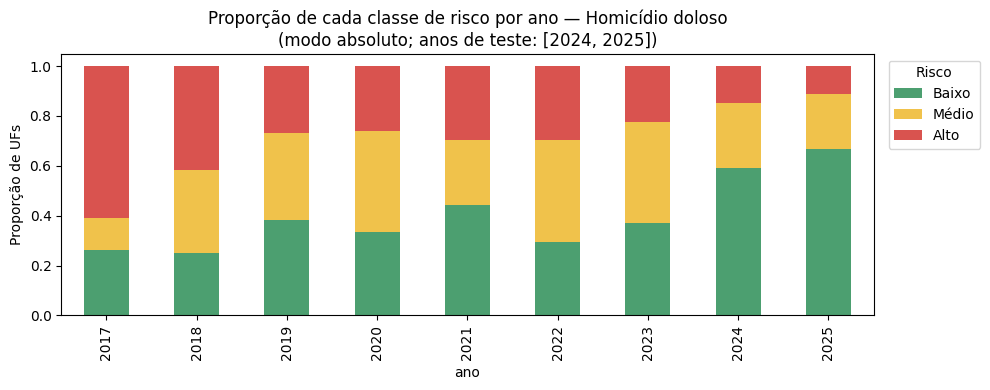


DERIVA: 63% das UFs do teste caem em 'Baixo' (no treino é ~33%). A taxa muda ao longo do tempo e os limites do treino ficam defasados. Compare com o modo 'relativo' na seção 11.1.


In [ ]:
CLASSES = ["Baixo", "Médio", "Alto"]
ORDEM = {c: i for i, c in enumerate(CLASSES)}


def limites_tercis(taxas):
    return float(taxas.quantile(1 / 3)), float(taxas.quantile(2 / 3))


def rotular_absoluto(taxas, t1, t2):
    """Classifica pela taxa. Com n múltiplo de 3 o tercil cai EXATAMENTE sobre um valor observado;
    sem tolerância, um erro de 1 bit de ponto flutuante (que varia entre versões do pandas/numpy)
    mudaria a UF de classe. A tolerância torna o resultado reprodutível."""
    tol = 1e-9
    r = pd.Series(
        np.select(
            [taxas <= t1 * (1 + tol) + tol, taxas <= t2 * (1 + tol) + tol],
            ["Baixo", "Médio"], default="Alto",
        ),
        index=taxas.index, dtype="object",
    )
    return r.where(taxas.notna())


def rotular_relativo(df, coluna):
    """Tercis dentro de cada ano (usa a posição no ranking para evitar empates)."""
    def _tercis(s):
        if s.notna().sum() < 3:
            return pd.Series(np.nan, index=s.index, dtype="object")
        return pd.qcut(s.rank(method="first"), 3, labels=CLASSES).astype("object")
    return df.groupby("ano")[coluna].transform(_tercis)


def rotular_treino(df, modo):
    if modo == "absoluto":
        t1, t2 = limites_tercis(df["taxa_alvo_100k"])
        return rotular_absoluto(df["taxa_alvo_100k"], t1, t2), {"tercil_1": t1, "tercil_2": t2}
    return rotular_relativo(df, "taxa_alvo_100k"), None


def rotular(treino_df, teste_df, modo):
    """Rótulos do treino, do teste e da baseline de persistência (classe do ano anterior)."""
    y_tr, limites = rotular_treino(treino_df, modo)
    if modo == "absoluto":
        t1, t2 = limites["tercil_1"], limites["tercil_2"]
        y_te = rotular_absoluto(teste_df["taxa_alvo_100k"], t1, t2)
        y_pers = rotular_absoluto(teste_df["taxa_alvo_100k_lag1"], t1, t2)
    else:
        y_te = rotular_relativo(teste_df, "taxa_alvo_100k")
        y_pers = rotular_relativo(teste_df, "taxa_alvo_100k_lag1")
    return y_tr, y_te, y_pers, limites


# ---- Funil: quantas linhas sobram em cada etapa ----
n_total = len(painel)
validas_alvo = painel.dropna(subset=["taxa_alvo_100k"])
elegiveis = validas_alvo.dropna(subset=["taxa_alvo_100k_lag1", "taxa_alvo_100k_lag2"])

display(pd.DataFrame({
    "etapa": [
        "UF×ano no painel",
        "com alvo reportado (taxa válida)",
        "com lag1 e lag2 válidos (elegíveis à modelagem)",
    ],
    "linhas": [n_total, len(validas_alvo), len(elegiveis)],
}))

excluidas_alvo = painel.loc[painel["taxa_alvo_100k"].isna(), ["ano", "uf"]]
if len(excluidas_alvo):
    print("UF×ano excluídas por ALVO não reportado:")
    display(excluidas_alvo.groupby("ano")["uf"].apply(lambda s: ", ".join(sorted(s))).reset_index(name="ufs"))

# ---- Separação temporal (antes dos limites de risco) ----
painel_modelo = elegiveis.replace([np.inf, -np.inf], np.nan).copy()
if ANO_INICIAL_MODELAGEM is not None:
    painel_modelo = painel_modelo[painel_modelo["ano"] >= ANO_INICIAL_MODELAGEM].copy()
    print(f"ANO_INICIAL_MODELAGEM = {ANO_INICIAL_MODELAGEM}: linhas de modelagem = {len(painel_modelo)}")

anos_modelo = sorted(painel_modelo["ano"].unique().tolist())
n_anos_teste = max(1, round(len(anos_modelo) * PROPORCAO_TESTE_ANOS))
anos_teste = anos_modelo[-n_anos_teste:]
anos_treino = [a for a in anos_modelo if a not in anos_teste]

treino = painel_modelo[painel_modelo["ano"].isin(anos_treino)].copy()
teste = painel_modelo[painel_modelo["ano"].isin(anos_teste)].copy()

print("\nAnos disponíveis para modelagem:", anos_modelo)
print("Anos de treino:", anos_treino)
print("Anos de teste :", anos_teste)

# ---- Rótulos do cenário principal ----
y_treino, y_teste, y_pers_teste, limites_principal = rotular(treino, teste, MODO_RISCO_PRINCIPAL)
painel_modelo.loc[treino.index, "risco"] = y_treino
painel_modelo.loc[teste.index, "risco"] = y_teste

if limites_principal:
    tercil_1, tercil_2 = limites_principal["tercil_1"], limites_principal["tercil_2"]
    print(f"\nTercil 1 (treino): {tercil_1:.2f} | Tercil 2 (treino): {tercil_2:.2f}")

print("\nDistribuição no TREINO:")
display(y_treino.value_counts().reindex(CLASSES))
print("Distribuição no TESTE:")
display(y_teste.value_counts().reindex(CLASSES))

# ---- Deriva: distribuição das classes por ano ----
dist = pd.crosstab(painel_modelo["ano"], painel_modelo["risco"]).reindex(columns=CLASSES, fill_value=0)
dist_pct = dist.div(dist.sum(axis=1), axis=0)

ax = dist_pct.plot(kind="bar", stacked=True, figsize=(10, 4), color=["#4c9f70", "#f0c24b", "#d9534f"])
ax.set_title(f"Proporção de cada classe de risco por ano — {INDICADOR_ALVO}\n(modo {MODO_RISCO_PRINCIPAL}; anos de teste: {anos_teste})")
ax.set_ylabel("Proporção de UFs")
ax.legend(title="Risco", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

if MODO_RISCO_PRINCIPAL == "absoluto":
    pct_baixo_teste = float((y_teste == "Baixo").mean())
    if abs(pct_baixo_teste - 1 / 3) > 0.15:
        print(f"\nDERIVA: {pct_baixo_teste:.0%} das UFs do teste caem em 'Baixo' (no treino é ~33%). "
              "A taxa muda ao longo do tempo e os limites do treino ficam defasados. "
              "Compare com o modo 'relativo' na seção 11.1.")

## 9. Separação treino/teste por ano e conjuntos de atributos

Para simular o uso real (estimar o risco de anos recentes com base em anos anteriores), a separação é **por ano**, não aleatória: os anos mais recentes completos ficam para teste.

A **UF** entra como atributo categórico (one-hot). Se a UF "decora" o nível de cada estado, isso aparece na importância por permutação (seção 13).

In [ ]:
conjunto_principal = CONJUNTOS_ATRIBUTOS[CONJUNTO_ATRIBUTOS_PRINCIPAL]
ATRIBUTOS_NUMERICOS = conjunto_principal["numericos"]
ATRIBUTOS_CATEGORICOS = conjunto_principal["categoricos"]
atributos = ATRIBUTOS_NUMERICOS + ATRIBUTOS_CATEGORICOS

X_treino, X_teste = treino[atributos], teste[atributos]

print("Registros de treino:", len(X_treino))
print("Registros de teste :", len(X_teste))
print("Atributos utilizados:", len(atributos), f"({CONJUNTO_ATRIBUTOS_PRINCIPAL})")
print("Valores ausentes por atributo (treino), só os que têm:")
ausentes_treino = X_treino.isna().sum()
display(ausentes_treino[ausentes_treino > 0].to_frame("n_ausentes"))

Registros de treino: 181
Registros de teste : 54
Atributos utilizados: 14 (mesmo_ano)
Valores ausentes por atributo (treino), só os que têm:


,n_ausentes
taxa_estupro_100k,1
taxa_estupro_de_vulneravel_100k,41
taxa_tentativa_de_homicidio_100k,6
taxa_trafico_de_drogas_100k,3


## 10. Pipeline de pré-processamento

- **Numéricos:** imputação pela mediana **com indicador de ausência** (`add_indicator=True`, assim o modelo sabe que o valor era "não reportado") + padronização;
- **UF (categórico):** imputação pela moda + one-hot.

Só componentes padrão do scikit-learn, para o `.joblib` poder ser carregado fora do notebook. **Cada pipeline recebe uma cópia nova** do pré-processador (antes os três compartilhavam o mesmo objeto).

In [ ]:
def montar_preprocessamento(numericos, categoricos):
    return ColumnTransformer(transformers=[
        ("numericas", Pipeline(steps=[
            ("imputador", SimpleImputer(strategy="median", add_indicator=True)),
            ("padronizador", StandardScaler()),
        ]), numericos),
        ("categoricas", Pipeline(steps=[
            ("imputador_uf", SimpleImputer(strategy="most_frequent")),
            ("onehot_uf", OneHotEncoder(handle_unknown="ignore")),
        ]), categoricos),
    ])


def criar_modelos():
    """Modelos novos (sem estado) a cada chamada."""
    return {
        "Dummy (estratificado)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
        "Dummy (mais frequente)": DummyClassifier(strategy="most_frequent"),
        # Regularização forte (C menor) e limites de complexidade no RF: poucas linhas de treino.
        "Regressão Logística": LogisticRegression(max_iter=2000, C=0.5, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=4, min_samples_leaf=3,
            max_features="sqrt", random_state=RANDOM_STATE,
        ),
    }


def criar_pipeline(modelo, numericos, categoricos):
    return Pipeline(steps=[
        ("pre_processamento", montar_preprocessamento(numericos, categoricos)),
        ("modelo", modelo),
    ])


PERSISTENCIA = "Persistência (ano anterior)"
MODELOS_TREINAVEIS = ["Regressão Logística", "Random Forest"]


def metricas(y_true, y_pred):
    """Acurácia, F1-macro e métricas ordinais (kappa quadrático, erro grave Baixo<->Alto)."""
    y_true = pd.Series(y_true).reset_index(drop=True)
    y_pred = pd.Series(np.asarray(y_pred, dtype=object))
    yt, yp = y_true.map(ORDEM).to_numpy(dtype=float), y_pred.map(ORDEM).to_numpy(dtype=float)
    try:
        kappa = cohen_kappa_score(yt, yp, labels=[0, 1, 2], weights="quadratic")
    except Exception:
        kappa = np.nan
    return {
        "acuracia": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "kappa_quadratico": kappa,
        "erro_grave": float((np.abs(yt - yp) == 2).mean()),
    }


print("Pré-processamento e utilitários definidos.")

Pré-processamento e utilitários definidos.


## 11. Modelos e baselines — holdout (anos de teste)

Comparação no **cenário principal**. Referências:

- **Dummy (estratificado / mais frequente):** pisos mínimos.
- **Persistência (ano anterior):** *prevê para cada UF a classe que ela teria se tivesse a taxa do ano anterior.* Não aprende nada. **Se o modelo não superar a persistência, ele não está agregando informação além de "repetir o ano passado".**

Métricas: acurácia, **F1-macro**, **kappa quadrático** (concordância ordinal; 1 = perfeito, 0 = acaso) e **erro grave** (fração de previsões que erram por dois níveis, Baixo↔Alto; menor é melhor).

> Com poucas linhas no teste, as diferenças de 1–3 pontos não são conclusivas; a decisão usa a validação walk-forward (11.1).

In [ ]:
def avaliar_holdout(treino_df, teste_df, conjunto, modo):
    conj = CONJUNTOS_ATRIBUTOS[conjunto]
    num, cat = conj["numericos"], conj["categoricos"]
    attrs = num + cat

    y_tr, y_te, y_pers, limites = rotular(treino_df, teste_df, modo)

    linhas = [{"modelo": PERSISTENCIA, **metricas(y_te, y_pers)}]
    pipelines, previsoes = {}, {PERSISTENCIA: y_pers.to_numpy()}

    for nome, modelo in criar_modelos().items():
        pipe = criar_pipeline(modelo, num, cat)
        pipe.fit(treino_df[attrs], y_tr)
        pred = pipe.predict(teste_df[attrs])
        linhas.append({"modelo": nome, **metricas(y_te, pred)})
        pipelines[nome], previsoes[nome] = pipe, pred

    tabela = pd.DataFrame(linhas).sort_values("f1_macro", ascending=False).reset_index(drop=True)
    return tabela, pipelines, previsoes, y_tr, y_te, limites


tabela_resultados, pipelines_treinados, previsoes_teste, y_treino, y_teste, _ = avaliar_holdout(
    treino, teste, CONJUNTO_ATRIBUTOS_PRINCIPAL, MODO_RISCO_PRINCIPAL
)

for nome in MODELOS_TREINAVEIS:
    print(f"\n=== {nome} ===")
    print(classification_report(y_teste, previsoes_teste[nome], zero_division=0))

print("\nResultados no holdout (anos de teste):", anos_teste)
display(tabela_resultados.round(4))

# ---- Carimbo de reprodutibilidade: compare com o de outra execução para achar diferenças ----
import hashlib
_dados_ref = (
    painel_modelo[["ano", "uf", "taxa_alvo_100k"]]
    .sort_values(["ano", "uf"]).round(6).to_csv(index=False)
)
print("\n--- Carimbo de reprodutibilidade ---")
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("linhas de modelagem:", len(painel_modelo), "| treino:", len(treino), "| teste:", len(teste))
if limites_principal:
    print(f"tercis do treino: {limites_principal['tercil_1']:.6f} / {limites_principal['tercil_2']:.6f}")
print("classes treino:", y_treino.value_counts().reindex(CLASSES).tolist(),
      "| classes teste:", y_teste.value_counts().reindex(CLASSES).tolist())
print("impressão digital dos dados (taxa do alvo):", hashlib.md5(_dados_ref.encode()).hexdigest()[:10])
print("F1-macro holdout:", tabela_resultados.set_index("modelo")["f1_macro"].round(4).to_dict())


=== Regressão Logística ===
              precision    recall  f1-score   support

        Alto       0.88      1.00      0.93         7
       Baixo       0.92      0.68      0.78        34
       Médio       0.48      0.77      0.59        13

    accuracy                           0.74        54
   macro avg       0.76      0.82      0.77        54
weighted avg       0.81      0.74      0.75        54


=== Random Forest ===
              precision    recall  f1-score   support

        Alto       0.88      1.00      0.93         7
       Baixo       0.96      0.76      0.85        34
       Médio       0.58      0.85      0.69        13

    accuracy                           0.81        54
   macro avg       0.81      0.87      0.82        54
weighted avg       0.86      0.81      0.82        54


Resultados no holdout (anos de teste): [2024, 2025]


,modelo,acuracia,f1_macro,kappa_quadratico,erro_grave
0,Random Forest,0.8148,0.8244,0.8246,0.0000
1,Regressão Logística,0.7407,0.7671,0.7544,0.0000
2,Persistência (ano anterior),0.7593,0.7458,0.7869,0.0000
3,Dummy (estratificado),0.3704,0.3205,-0.0380,0.2963
4,Dummy (mais frequente),0.6296,0.2576,0.0000,0.1296



--- Carimbo de reprodutibilidade ---
pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1
linhas de modelagem: 235 | treino: 181 | teste: 54
tercis do treino: 20.664817 / 27.499089
classes treino: [61, 60, 60] | classes teste: [34, 13, 7]
impressão digital dos dados (taxa do alvo): d9c4db2d61
F1-macro holdout: {'Random Forest': 0.8244, 'Regressão Logística': 0.7671, 'Persistência (ano anterior)': 0.7458, 'Dummy (estratificado)': 0.3205, 'Dummy (mais frequente)': 0.2576}


## 11.1 Validação walk-forward e análise de robustez

Um único corte treino/teste (poucos anos, poucas UFs) pode ser pouco representativo. Aqui, a cada rodada o modelo treina com todos os anos **anteriores** a `k` e testa no ano `k` — avançando até o fim da série. **Os limites de risco são recalculados a cada rodada só com o treino daquela rodada.**

A célula roda **os 4 cenários** (modo de risco × conjunto de atributos) para mostrar o quanto o resultado depende dessas escolhas:

| | atributos **mesmo ano** | atributos **só histórico** |
|---|---|---|
| risco **absoluto** | *cenário principal* | previsão real, limites fixos |
| risco **relativo** | estima a posição relativa no ano | previsão real, posição relativa |

**Importante para o relatório:** o cenário *mesmo ano* usa os outros indicadores do **próprio ano** (ex.: tentativas de homicídio de 2024 para estimar o risco de homicídio de 2024). Isso é uma estimativa contemporânea, não uma previsão. O cenário *só histórico* é a previsão de fato (usa só o que se sabia até o ano anterior).

In [ ]:
def walk_forward(painel_m, conjunto, modo, minimo_anos_treino=2):
    conj = CONJUNTOS_ATRIBUTOS[conjunto]
    num, cat = conj["numericos"], conj["categoricos"]
    attrs = num + cat
    anos = sorted(painel_m["ano"].unique().tolist())
    linhas = []

    for i, ano_teste in enumerate(anos):
        anos_tr = anos[:i]
        if len(anos_tr) < minimo_anos_treino:
            continue

        tr = painel_m[painel_m["ano"].isin(anos_tr)]
        te = painel_m[painel_m["ano"] == ano_teste]
        if tr.empty or te.empty:
            continue

        y_tr, y_te, y_pers, _ = rotular(tr, te, modo)
        if y_tr.nunique() < 2:
            continue

        base = {"modo_risco": modo, "atributos": conjunto, "ano_teste": ano_teste,
                "n_treino": len(tr), "n_teste": len(te)}
        linhas.append({**base, "modelo": PERSISTENCIA, **metricas(y_te, y_pers)})

        for nome, modelo in criar_modelos().items():
            pipe = criar_pipeline(modelo, num, cat)
            try:
                pipe.fit(tr[attrs], y_tr)
                pred = pipe.predict(te[attrs])
            except Exception as erro:
                print(f"Rodada {ano_teste} / {nome} falhou: {erro}")
                continue
            linhas.append({**base, "modelo": nome, **metricas(y_te, pred)})

    return pd.DataFrame(linhas)


CENARIOS = [
    ("absoluto", "mesmo_ano"),
    ("absoluto", "so_historico"),
    ("relativo", "mesmo_ano"),
    ("relativo", "so_historico"),
]

resultados_wf_todos = pd.concat(
    [walk_forward(painel_modelo.drop(columns=["risco"]), conj, modo) for modo, conj in CENARIOS],
    ignore_index=True,
)

if resultados_wf_todos.empty:
    print("Não foi possível rodar a validação walk-forward (poucos anos disponíveis).")
else:
    resumo_cenarios = (
        resultados_wf_todos
        .groupby(["modo_risco", "atributos", "modelo"])["f1_macro"]
        .agg(["mean", "std"]).round(3)
        .unstack("modelo")
    )
    print("F1-macro médio (e desvio-padrão) por cenário, entre as rodadas walk-forward:")
    display(resumo_cenarios["mean"])
    print("Desvio-padrão entre rodadas:")
    display(resumo_cenarios["std"])

F1-macro médio (e desvio-padrão) por cenário, entre as rodadas walk-forward:


modelo                   Dummy (estratificado)  Dummy (mais frequente)  \
modo_risco atributos                                                     
absoluto   mesmo_ano                     0.323                   0.178   
           so_historico                  0.323                   0.178   
relativo   mesmo_ano                     0.397                   0.167   
           so_historico                  0.397                   0.167   

modelo                   Persistência (ano anterior)  Random Forest  \
modo_risco atributos                                                  
absoluto   mesmo_ano                           0.667          0.703   
           so_historico                        0.667          0.664   
relativo   mesmo_ano                           0.825          0.683   
           so_historico                        0.825          0.667   

modelo                   Regressão Logística  
modo_risco atributos                          
absoluto   mesmo_ano                   0.707  
           so_historico                0.711  
relativo   mesmo_ano                   0.676  
           so_historico                0.728

Desvio-padrão entre rodadas:


modelo                   Dummy (estratificado)  Dummy (mais frequente)  \
modo_risco atributos                                                     
absoluto   mesmo_ano                     0.055                   0.087   
           so_historico                  0.055                   0.087   
relativo   mesmo_ano                     0.051                   0.002   
           so_historico                  0.051                   0.002   

modelo                   Persistência (ano anterior)  Random Forest  \
modo_risco atributos                                                  
absoluto   mesmo_ano                           0.118          0.137   
           so_historico                        0.118          0.135   
relativo   mesmo_ano                           0.062          0.078   
           so_historico                        0.062          0.071   

modelo                   Regressão Logística  
modo_risco atributos                          
absoluto   mesmo_ano                   0.129  
           so_historico                0.131  
relativo   mesmo_ano                   0.065  
           so_historico                0.119

Walk-forward — cenário principal (absoluto | mesmo_ano):


acuracia         f1_macro          \
                                mean     std     mean     std   
modelo                                                          
Dummy (estratificado)         0.3724  0.0527   0.3227  0.0551   
Dummy (mais frequente)        0.3968  0.2103   0.1784  0.0867   
Persistência (ano anterior)   0.6962  0.0700   0.6669  0.1184   
Random Forest                 0.7444  0.0670   0.7025  0.1366   
Regressão Logística           0.7497  0.0681   0.7070  0.1285   

                            kappa_quadratico         erro_grave          
                                        mean     std       mean     std  
modelo                                                                   
Dummy (estratificado)                 0.1822  0.0831     0.1384  0.0187  
Dummy (mais frequente)                0.0000  0.0000     0.2359  0.1555  
Persistência (ano anterior)           0.7165  0.1011     0.0055  0.0145  
Random Forest                         0.7258  0.1142     0.0108  0.0184  
Regressão Logística                   0.7052  0.1555     0.0161  0.0293

modelo,Dummy (estratificado),Dummy (mais frequente),Persistência (ano anterior),Random Forest,Regressão Logística
ano_teste,,,,,
2019,0.274,0.000,0.433,0.496,0.499
2020,0.393,0.205,0.651,0.590,0.568
2021,0.257,0.205,0.645,0.657,0.727
2022,0.331,0.152,0.787,0.668,0.709
2023,0.388,0.180,0.780,0.817,0.803
2024,0.278,0.248,0.708,0.851,0.817
2025,0.338,0.258,0.664,0.838,0.827


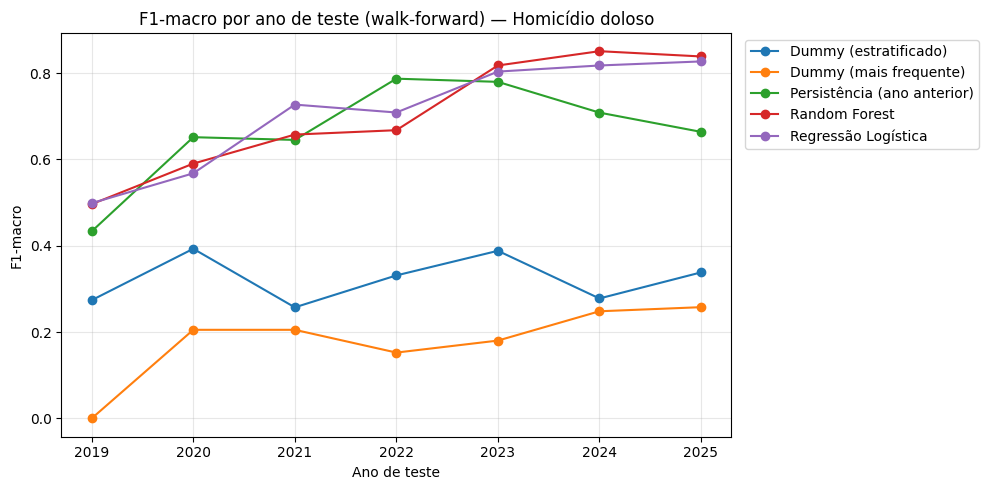

,rodadas_em_que_supera_a_persistencia,total_de_rodadas
Regressão Logística,5,7
Random Forest,5,7



Modelo escolhido (maior F1-macro médio no walk-forward): Regressão Logística
F1-macro walk-forward: modelo = 0.707 | persistência = 0.667 | diferença = +0.040


In [ ]:
# ---- Cenário principal em detalhe ----
resultados_wf = resultados_wf_todos[
    (resultados_wf_todos["modo_risco"] == MODO_RISCO_PRINCIPAL)
    & (resultados_wf_todos["atributos"] == CONJUNTO_ATRIBUTOS_PRINCIPAL)
]

resumo_wf = (
    resultados_wf.groupby("modelo")[["acuracia", "f1_macro", "kappa_quadratico", "erro_grave"]]
    .agg(["mean", "std"]).round(4)
)
print(f"Walk-forward — cenário principal ({MODO_RISCO_PRINCIPAL} | {CONJUNTO_ATRIBUTOS_PRINCIPAL}):")
display(resumo_wf)

f1_por_ano = resultados_wf.pivot(index="ano_teste", columns="modelo", values="f1_macro")
display(f1_por_ano.round(3))

ax = f1_por_ano.plot(marker="o", figsize=(10, 5))
ax.set_title(f"F1-macro por ano de teste (walk-forward) — {INDICADOR_ALVO}")
ax.set_xlabel("Ano de teste")
ax.set_ylabel("F1-macro")
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Em quantas rodadas cada modelo superou a persistência?
vitorias = pd.DataFrame({
    "rodadas_em_que_supera_a_persistencia": [
        int((f1_por_ano[m] > f1_por_ano[PERSISTENCIA]).sum()) for m in MODELOS_TREINAVEIS
    ],
    "total_de_rodadas": len(f1_por_ano),
}, index=MODELOS_TREINAVEIS)
display(vitorias)

# ---- ESCOLHA DO MODELO: pelo walk-forward (não pelo teste) ----
candidatos = resultados_wf[resultados_wf["modelo"].isin(MODELOS_TREINAVEIS)].groupby("modelo")["f1_macro"].mean()
melhor_modelo_nome = candidatos.idxmax()
print(f"\nModelo escolhido (maior F1-macro médio no walk-forward): {melhor_modelo_nome}")

f1_modelo = float(candidatos[melhor_modelo_nome])
f1_pers = float(resultados_wf.loc[resultados_wf["modelo"] == PERSISTENCIA, "f1_macro"].mean())
print(f"F1-macro walk-forward: modelo = {f1_modelo:.3f} | persistência = {f1_pers:.3f} | diferença = {f1_modelo - f1_pers:+.3f}")
if f1_modelo - f1_pers < 0.03:
    print("-> O ganho sobre 'repetir o ano anterior' é pequeno. Reporte isso no artigo: o modelo "
          "pouco acrescenta além da persistência neste cenário.")

## 12. Matriz de confusão do modelo escolhido (holdout)

À esquerda, contagens; à direita, normalizada por linha (em cada classe **real**, que fração foi prevista como cada classe).

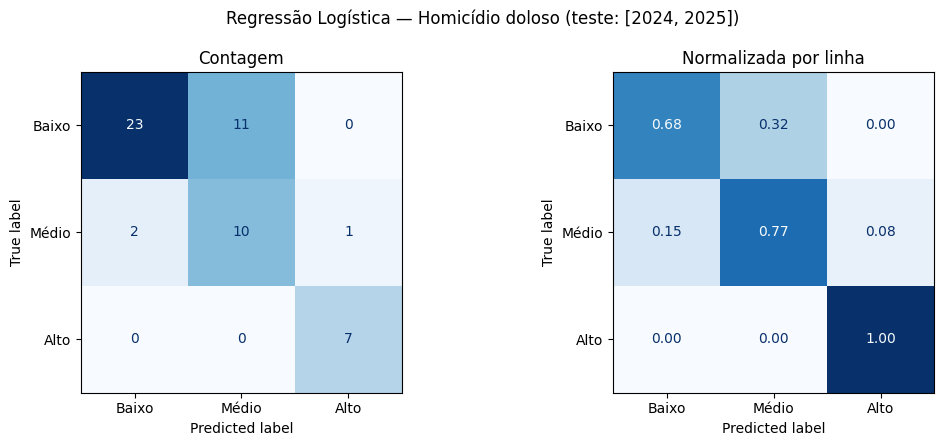

Métricas do modelo escolhido no holdout:


,modelo,acuracia,f1_macro,kappa_quadratico,erro_grave
1,Regressão Logística,0.7407,0.7671,0.7544,0.0


In [ ]:
melhor_pipeline = pipelines_treinados[melhor_modelo_nome]
y_previsto_melhor = previsoes_teste[melhor_modelo_nome]

matriz = confusion_matrix(y_teste, y_previsto_melhor, labels=CLASSES)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(matriz, display_labels=CLASSES).plot(ax=eixos[0], cmap="Blues", colorbar=False)
eixos[0].set_title("Contagem")
ConfusionMatrixDisplay(
    confusion_matrix(y_teste, y_previsto_melhor, labels=CLASSES, normalize="true"),
    display_labels=CLASSES,
).plot(ax=eixos[1], cmap="Blues", colorbar=False, values_format=".2f")
eixos[1].set_title("Normalizada por linha")
fig.suptitle(f"{melhor_modelo_nome} — {INDICADOR_ALVO} (teste: {anos_teste})")
plt.tight_layout()
plt.show()

print("Métricas do modelo escolhido no holdout:")
display(tabela_resultados[tabela_resultados["modelo"] == melhor_modelo_nome].round(4))

## 13. Importância dos atributos (permutação)

A **importância por permutação** mede quanto o F1-macro **cai no teste** quando os valores de um atributo são embaralhados. É mais confiável que a importância por impureza do Random Forest (enviesada com atributos correlacionados e variáveis one-hot). A UF é tratada como **um** atributo.

Atenção: com poucas linhas de teste a medida é ruidosa — observe as barras de erro. Um atributo é relevante apenas se a barra não incluir zero com folga. Se `taxa_alvo_100k_lag1` dominar, o modelo está, na prática, apoiado no histórico do próprio indicador.

,atributo,queda_f1_media,desvio
0,taxa_alvo_100k_lag1,0.2821,0.0810
13,uf,0.1512,0.0443
4,taxa_estupro_de_vulneravel_100k,0.0442,0.0553
3,taxa_estupro_100k,-0.0000,0.0181
1,variacao_pct_alvo,-0.0012,0.0045
11,taxa_trafico_de_drogas_100k,-0.0035,0.0144
10,taxa_tentativa_de_homicidio_100k,-0.0037,0.0242
12,taxa_total_outros_100k,-0.0116,0.0103
9,taxa_tentativa_de_feminicidio_100k,-0.0170,0.0294
8,taxa_roubo_seguido_de_morte_latrocinio_100k,-0.0183,0.0185


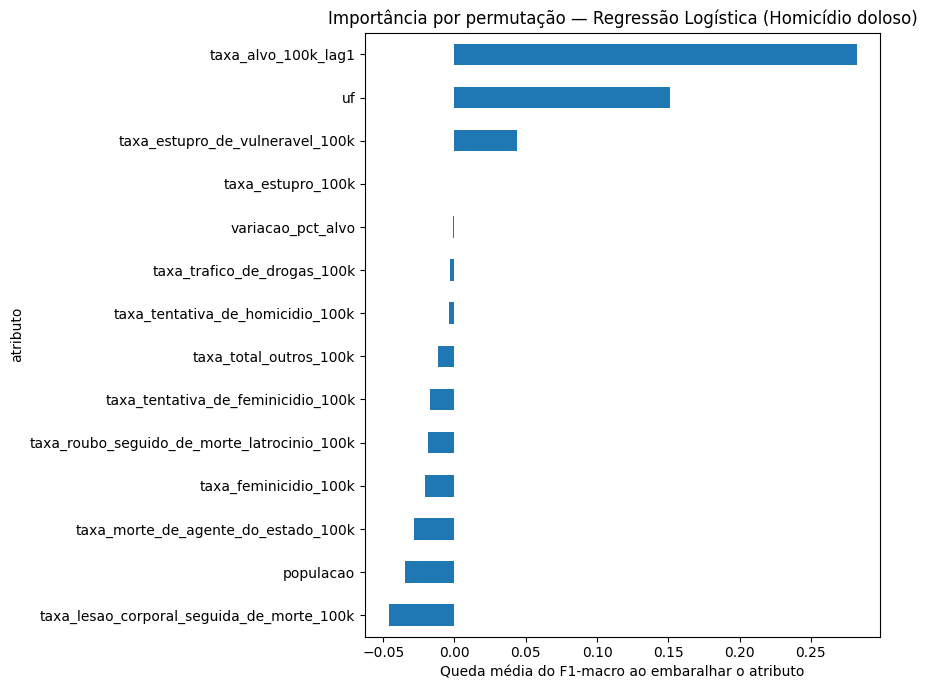

In [ ]:
perm = permutation_importance(
    melhor_pipeline, X_teste, y_teste,
    scoring="f1_macro", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1,
)

importancias = (
    pd.DataFrame({
        "atributo": X_teste.columns,
        "queda_f1_media": perm.importances_mean,
        "desvio": perm.importances_std,
    })
    .sort_values("queda_f1_media", ascending=False)
    .head(15)
)
display(importancias.round(4))

d = importancias.sort_values("queda_f1_media")
ax = d.plot(
    x="atributo", y="queda_f1_media", kind="barh", xerr=d["desvio"],
    figsize=(9, 7), legend=False,
    title=f"Importância por permutação — {melhor_modelo_nome} ({INDICADOR_ALVO})",
)
ax.set_xlabel("Queda média do F1-macro ao embaralhar o atributo")
plt.tight_layout()
plt.show()

## 13.1 Versão alternativa: risco binário (Baixo vs. Não-Baixo)

A classe "Alto" costuma ter poucos casos no teste (veja a seção 8), o que deixa as métricas por classe instáveis. Esta seção reagrupa "Médio" e "Alto" em "Não-Baixo". É um cenário **complementar** (não substitui a análise de 3 classes). A persistência também é avaliada aqui.

In [ ]:
def binarizar(serie):
    return pd.Series(np.where(pd.Series(serie).to_numpy() == "Baixo", "Baixo", "Não-Baixo"))


y_tr_bin = binarizar(y_treino).to_numpy()
y_te_bin = binarizar(y_teste)

resultados_bin = []
pred_pers_bin = binarizar(y_pers_teste)
resultados_bin.append({
    "modelo": PERSISTENCIA,
    "acuracia": accuracy_score(y_te_bin, pred_pers_bin),
    "f1_macro": f1_score(y_te_bin, pred_pers_bin, average="macro", zero_division=0),
})

for nome, modelo in criar_modelos().items():
    pipe_b = criar_pipeline(modelo, ATRIBUTOS_NUMERICOS, ATRIBUTOS_CATEGORICOS)
    pipe_b.fit(X_treino, y_tr_bin)
    pred_b = pipe_b.predict(X_teste)
    resultados_bin.append({
        "modelo": nome,
        "acuracia": accuracy_score(y_te_bin, pred_b),
        "f1_macro": f1_score(y_te_bin, pred_b, average="macro", zero_division=0),
    })
    if nome in MODELOS_TREINAVEIS:
        print(f"\n=== {nome} (binário: Baixo vs Não-Baixo) ===")
        print(classification_report(y_te_bin, pred_b, zero_division=0))

tabela_resultados_bin = pd.DataFrame(resultados_bin).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(tabela_resultados_bin.round(4))


=== Regressão Logística (binário: Baixo vs Não-Baixo) ===
              precision    recall  f1-score   support

       Baixo       0.96      0.71      0.81        34
   Não-Baixo       0.66      0.95      0.78        20

    accuracy                           0.80        54
   macro avg       0.81      0.83      0.79        54
weighted avg       0.85      0.80      0.80        54


=== Random Forest (binário: Baixo vs Não-Baixo) ===
              precision    recall  f1-score   support

       Baixo       0.96      0.65      0.77        34
   Não-Baixo       0.61      0.95      0.75        20

    accuracy                           0.76        54
   macro avg       0.78      0.80      0.76        54
weighted avg       0.83      0.76      0.76        54



,modelo,acuracia,f1_macro
0,Persistência (ano anterior),0.8148,0.8125
1,Regressão Logística,0.7963,0.7945
2,Random Forest,0.7593,0.7585
3,Dummy (estratificado),0.5185,0.5159
4,Dummy (mais frequente),0.3704,0.2703


## 14. Modelo final, exportação e exemplo de uso

**Modelo final:** o algoritmo escolhido no walk-forward é **reajustado com todos os anos de modelagem** (treino + teste), pois é esse o modelo que será usado nas próximas etapas. Os limites de risco (tercis) são recalculados com todos esses anos.

> A nota de desempenho a reportar é a do **holdout / walk-forward** (seções 11–11.1), **não** a do modelo final: ele já viu todos os anos, então avaliá-lo nos mesmos dados seria otimista.

Arquivos gerados:

| Arquivo | Conteúdo |
|---|---|
| `modelos/modelo_risco_<alvo>.joblib` | pipeline final + metadados (atributos, limites, anos, versões) |
| `resultados/metricas_modelos_<alvo>.csv` | métricas do holdout |
| `resultados/walk_forward_<alvo>.csv` | métricas por rodada e cenário |
| `resultados/predicoes_teste_<alvo>.csv` | previsões por UF/ano no teste (entrada da Sprint 3 / mapas) |
| `resultados/painel_uf_ano_<alvo>.csv` | painel completo, com população, taxas, lags e risco |

In [ ]:
nome_arquivo_indicador = slug(INDICADOR_ALVO)

arquivo_modelo = PASTA_MODELOS / f"modelo_risco_{nome_arquivo_indicador}.joblib"
arquivo_metricas = PASTA_RESULTADOS / f"metricas_modelos_{nome_arquivo_indicador}.csv"
arquivo_wf = PASTA_RESULTADOS / f"walk_forward_{nome_arquivo_indicador}.csv"
arquivo_predicoes = PASTA_RESULTADOS / f"predicoes_teste_{nome_arquivo_indicador}.csv"
arquivo_painel = PASTA_RESULTADOS / f"painel_uf_ano_{nome_arquivo_indicador}.csv"

# ---- Reajuste final com todos os anos de modelagem ----
y_final, limites_final = rotular_treino(painel_modelo.drop(columns=["risco"]), MODO_RISCO_PRINCIPAL)

pipeline_final = criar_pipeline(
    criar_modelos()[melhor_modelo_nome], ATRIBUTOS_NUMERICOS, ATRIBUTOS_CATEGORICOS
)
pipeline_final.fit(painel_modelo[atributos], y_final)

metadados = {
    "pipeline": pipeline_final,
    "modelo": melhor_modelo_nome,
    "indicador_alvo": INDICADOR_ALVO,
    "cenario": {"modo_risco": MODO_RISCO_PRINCIPAL, "atributos": CONJUNTO_ATRIBUTOS_PRINCIPAL},
    "atributos": atributos,
    "atributos_numericos": ATRIBUTOS_NUMERICOS,
    "atributos_categoricos": ATRIBUTOS_CATEGORICOS,
    "classes": CLASSES,
    "limites_risco_modelo_final": limites_final,   # None no modo relativo (tercis por ano)
    "anos_treino_final": anos_modelo,
    "anos_treino_avaliacao": anos_treino,
    "anos_teste_avaliacao": anos_teste,
    "meses_sem_registro_tolerados": MESES_SEM_REGISTRO_TOLERADOS,
    "desempenho_walk_forward_f1_macro": f1_modelo,
    "desempenho_persistencia_f1_macro": f1_pers,
    "indicadores_utilizados": sorted(indicadores),
    "sklearn_version": sklearn.__version__,
    "versao_pipeline": "v5-10-indicadores",
}

joblib.dump(metadados, arquivo_modelo)

tabela_resultados.to_csv(arquivo_metricas, index=False, encoding="utf-8-sig")
resultados_wf_todos.to_csv(arquivo_wf, index=False, encoding="utf-8-sig")

predicoes = teste[["ano", "uf", "taxa_alvo_100k", "taxa_alvo_100k_lag1"]].copy()
predicoes["risco_real"] = y_teste.to_numpy()
predicoes["risco_previsto"] = previsoes_teste[melhor_modelo_nome]
predicoes["risco_persistencia"] = previsoes_teste[PERSISTENCIA]
predicoes["modelo"] = melhor_modelo_nome
predicoes.to_csv(arquivo_predicoes, index=False, encoding="utf-8-sig")

painel_export = painel.merge(painel_modelo[["ano", "uf", "risco"]], on=["ano", "uf"], how="left")
painel_export["alvo_reportado"] = painel_export["taxa_alvo_100k"].notna()
painel_export.to_csv(arquivo_painel, index=False, encoding="utf-8-sig")

print("Modelo exportado em :", arquivo_modelo)
print("Métricas            :", arquivo_metricas)
print("Walk-forward        :", arquivo_wf)
print("Previsões do teste  :", arquivo_predicoes)
print("Painel UF x ano     :", arquivo_painel)

Modelo exportado em : modelos/modelo_risco_homicidio_doloso.joblib
Métricas            : resultados/metricas_modelos_homicidio_doloso.csv
Walk-forward        : resultados/walk_forward_homicidio_doloso.csv
Previsões do teste  : resultados/predicoes_teste_homicidio_doloso.csv
Painel UF x ano     : resultados/painel_uf_ano_homicidio_doloso.csv


### Como usar o modelo exportado

O exemplo abaixo recarrega o `.joblib` e gera previsões. Para um **novo** ano, é preciso montar as mesmas colunas listadas em `atributos` (taxas do ano e `lag1`/`variacao_pct_alvo` calculados como na seção 7).

In [ ]:
carregado = joblib.load(arquivo_modelo)

ano_exemplo = max(anos_modelo)
X_exemplo = painel_modelo.loc[painel_modelo["ano"] == ano_exemplo, carregado["atributos"]]

previsao = carregado["pipeline"].predict(X_exemplo)
probas = pd.DataFrame(
    carregado["pipeline"].predict_proba(X_exemplo),
    columns=carregado["pipeline"].classes_, index=X_exemplo.index,
)[CLASSES].round(2)

exemplo = painel_modelo.loc[X_exemplo.index, ["uf", "ano", "taxa_alvo_100k"]].assign(risco_previsto=previsao).join(probas)
print(f"Modelo: {carregado['modelo']} | alvo: {carregado['indicador_alvo']} | cenário: {carregado['cenario']}")
display(exemplo.sort_values("taxa_alvo_100k", ascending=False).head(10))

# O modelo recarregado deve reproduzir exatamente o modelo em memória
assert (previsao == pipeline_final.predict(X_exemplo)).all()
print("Verificação: modelo recarregado == modelo em memória.")

Modelo: Regressão Logística | alvo: Homicídio doloso | cenário: {'modo_risco': 'absoluto', 'atributos': 'mesmo_ano'}


,uf,ano,taxa_alvo_100k,risco_previsto,Baixo,Médio,Alto
65,CE,2025,31.578938,Alto,0.02,0.23,0.75
175,PE,2025,30.150574,Alto,0.03,0.25,0.72
21,AL,2025,28.036095,Alto,0.02,0.21,0.77
109,MA,2025,25.861291,Médio,0.02,0.73,0.25
54,BA,2025,24.631988,Alto,0.12,0.40,0.48
219,RN,2025,23.847865,Baixo,0.56,0.41,0.03
230,RO,2025,23.630811,Médio,0.24,0.72,0.04
43,AP,2025,22.938140,Médio,0.16,0.81,0.03
164,PB,2025,21.611404,Médio,0.19,0.65,0.16
208,RJ,2025,19.403669,Médio,0.08,0.85,0.07


Verificação: modelo recarregado == modelo em memória.


## 15.Limitações

- **Poucos anos e poucas UFs:** ~25 UFs × ~7 anos modeláveis (poucas centenas de linhas). As métricas têm incerteza alta; diferenças de poucos pontos não são conclusivas.
- **Dado não reportado:** a regra "meses sem registro" é uma heurística. Pode marcar como não reportado um ano legítimo (UF pequena com um mês sem casos) ou deixar passar um não-reporte parcial. Ajuste `MESES_SEM_REGISTRO_TOLERADOS` e confira a lista (seção 4) contra as notas metodológicas do Sinesp. Indicadores de baixo volume não passam por essa checagem.
- **Classes por tercis** são uma simplificação, sem critério oficial de "risco" em segurança pública. No modo absoluto há **deriva temporal**; no relativo, a classe só diz a posição da UF naquele ano (não se o crime aumentou).
- **Cenário "mesmo ano":** usa outros indicadores do próprio ano, que são medidos juntos e podem ter a mesma causa (ex.: qualidade do registro da UF). Boa parte do desempenho pode refletir isso e a persistência da UF, não "capacidade de prever".
- **População:** 2023 é interpolada e há quebra metodológica entre as estimativas pré e pós Censo 2022, o que afeta levemente as taxas em torno desses anos.
- **A UF como atributo** permite ao modelo aprender o nível típico de cada estado; isso é útil, mas não é "explicação" de risco.
- O modelo é um **baseline**: não houve busca de hiperparâmetros nem atributos espaciais (autocorrelação espacial, vizinhança — Moran/LISA), previstos para etapas seguintes.
- A importância por permutação, com poucas linhas de teste, é ruidosa.
- Este notebook **não estabelece relação causal**; trata-se de um modelo preditivo/exploratório.
- O código foi validado com dados sintéticos no formato do Sinesp VDE; os resultados numéricos reais dependem dos seus dados.